# EUR/USD daily returns — ARMA–GARCH with makystats

**Series.** Daily log-returns of **USD per EUR** (FRED `DEXUSEU`), percent, **2005-01-03 → 2019-12-31**.

**Pedagogical role.** FX returns are a classic **GARCH** laboratory. Mean dynamics are usually **weak**. The notebook deliberately tests AR/MA and shows — with BIC and residual tests — when **not** to keep them. That is still a demonstration of makystats power: joint MLE + honest model comparison, not forcing ARMA(1,1).

**Links.** [PyPI](https://pypi.org/project/makystats/) · [Docs](https://lauret-boris.github.io/makystats/) · [GitHub](https://github.com/Lauret-Boris/makystats)


## 1. Setup


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from makystats import arma_garch, select_order
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.0)

## 2. Data


In [5]:
path="data/eurusd_daily.csv"
df = pd.read_csv(path, parse_dates=True, index_col=0)
y = df["logret"].dropna().astype(float)
y.name = "EURUSD_logret"
print(path, y.index.min().date(), "→", y.index.max().date(), len(y))
y.describe().round(4)

data/eurusd_daily.csv 2005-01-04 → 2019-12-31 3761


count    3761.0000
mean       -0.0049
std         0.5904
min        -3.0031
25%        -0.3210
50%         0.0000
75%         0.3055
max         4.6208
Name: EURUSD_logret, dtype: float64

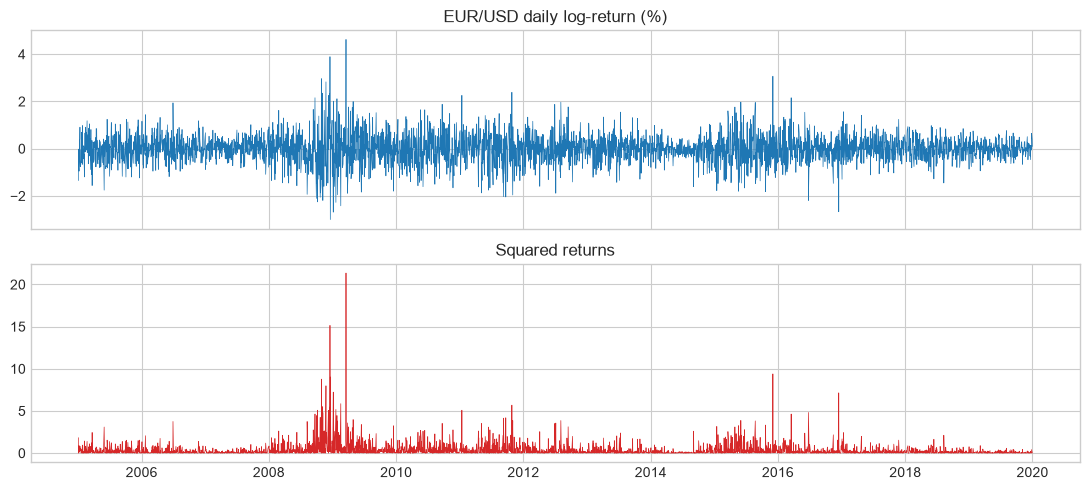

Ljung–Box levels


,lb_stat,lb_pvalue
5,4.4031,0.4930
10,9.2296,0.5105
20,11.6211,0.9285


Ljung–Box squares


,lb_stat,lb_pvalue
5,276.2916,0.0
10,601.1048,0.0
20,1189.7280,0.0


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(y, lw=0.5)
axes[0].set_title("EUR/USD daily log-return (%)")
axes[1].plot(y**2, lw=0.5, color="C3")
axes[1].set_title("Squared returns")
fig.tight_layout()
plt.show()

def lb(s, title):
    d = acorr_ljungbox(s, lags=[5, 10, 20], return_df=True)
    print(title); display(d.round(4))
lb(y - y.mean(), "Ljung–Box levels")
lb((y - y.mean())**2, "Ljung–Box squares")


**Reading.** Level dependence is **weak or absent**; squared returns are **strongly** dependent. Theory (approx. efficient FX market at daily horizon) agrees: **variance first**, mean only if residual tests insist.


## 3. Step A — Constant + GARCH(1,1) normal


In [7]:
def report(name, res):
    print("=== %s ===" % name)
    print("LogL=%.2f  AIC=%.2f  BIC=%.2f" % (res.loglik, res.aic, res.bic))
    print("LB resid p=%.4g | LB resid2 p=%.4g | JB p=%.4g" % (
        res.ljungbox_resid_pval, res.ljungbox_resid2_pval, res.jarque_bera_pval))
    display(res.coef_table.round(4))

res_A = arma_garch(y, mean="Constant", ar=0, ma=0, vol="GARCH", r=1, s=1, dist="normal", trend="c").fit(verbose=False)
res_A.summary()


   ARMA(0,0) - GARCH(1,1) — MLE (MLE)
   Mean: Constant  |  trend=c  |  Distribution: NORMAL  |  Optimiseur: BFGS non contraint (reparam.)
   Backcast exponentiel: lambda = 0.7  |  Cov: OPG
Log-Likelihood : -2983.309054
AIC            : 5974.6181
BIC            : 5999.5479
Observations   : 3761
Paramètres     : 4

--- Coefficients (IC 95% dans self.coef_table) ---
             Coeff   Std.Err      z-Stat     Prob.  CI_low_95  CI_high_95
const    -0.000298  0.007961   -0.037402  0.970164  -0.015900    0.015305
omega     0.000817  0.000175    4.663324  0.000003   0.000474    0.001161
alpha(1)  0.032086  0.003175   10.105524  0.000000   0.025863    0.038309
beta(1)   0.965409  0.003185  303.068660  0.000000   0.959166    0.971652

--- Diagnostic ---
alpha+beta = 0.997495
Ljung-Box (10) sur résidus std : p-val = 0.9518
Ljung-Box (10) sur carrés std  : p-val = 0.5638
Jarque-Bera (normalité résidus std) : stat=258.9144  p-val=0.0000


**Diagnosis A.** Residual level Ljung–Box is typically **comfortable** after GARCH alone. Jarque–Bera still fails → try Student-t. ARMA is **not** required yet.


## 4. Step B — Do AR/MA help under GARCH?


In [8]:
cands = {}
for name, kw in [
    ("Const+G", dict(mean="Constant", ar=0, ma=0)),
    ("AR(1)+G", dict(mean="AR", ar=1, ma=0)),
    ("MA(1)+G", dict(mean="ARMA", ar=0, ma=1)),
    ("ARMA(1,1)+G", dict(mean="ARMA", ar=1, ma=1)),
]:
    cands[name] = arma_garch(y, vol="GARCH", r=1, s=1, dist="normal", trend="c", **kw).fit(verbose=False)
    
comp = pd.DataFrame([
    {"model": k, "AIC": v.aic, "BIC": v.bic,
     "LB_resid_p": v.ljungbox_resid_pval, "LB_resid2_p": v.ljungbox_resid2_pval}
    for k, v in cands.items()
]).set_index("model")
display(comp.round(4))
print("ARMA(1,1) coefficients (watch for near cancellation):")
display(cands["ARMA(1,1)+G"].coef_table.round(4))

,AIC,BIC,LB_resid_p,LB_resid2_p
model,,,,
Const+G,5974.6181,5999.5479,0.9518,0.5638
AR(1)+G,5966.0067,5997.1675,0.9734,0.5537
MA(1)+G,5972.3722,6003.5331,0.9787,0.5634
"ARMA(1,1)+G",5967.7799,6005.1729,0.9519,0.5552


ARMA(1,1) coefficients (watch for near cancellation):


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0002,0.0080,0.0226,0.9819,-0.0154,0.0158
AR(1),-0.9900,0.0194,-51.1607,0.0000,-1.0279,-0.9521
MA(1),0.9897,0.0195,50.7870,0.0000,0.9516,1.0279
omega,0.0007,0.0002,4.3608,0.0000,0.0004,0.0011
alpha(1),0.0309,0.0031,9.8668,0.0000,0.0248,0.0371
beta(1),0.9669,0.0032,304.7479,0.0000,0.9607,0.9731


**Diagnosis B.** BIC usually prefers **constant mean**. ARMA(1,1) often shows **AR ≈ −MA ≈ ±1** (cancellation): extra parameters without economic content. **Do not keep ARMA** on that basis.


## 5. Step C — Student-t innovations (and optional GJR)


In [10]:
res_C = arma_garch(
    y, mean="Constant", ar=0, ma=0, vol="GARCH", r=1, s=1, dist="t", trend="c"
).fit(verbose=False)
report("C — Constant + GARCH(1,1) Student-t", res_C)

res_Cj = arma_garch(
    y, mean="Constant", ar=0, ma=0, vol="GJR", r=1, s=1, o=1, dist="t", trend="c"
).fit(verbose=False)
report("C2 — Constant + GJR(1,1) Student-t", res_Cj)

ic = pd.DataFrame({
    "GARCH-n": [cands["Const+G"].aic, cands["Const+G"].bic],
    "GARCH-t": [res_C.aic, res_C.bic],
    "GJR-t": [res_Cj.aic, res_Cj.bic],
}, index=["AIC", "BIC"])
display(ic.round(2))

=== C — Constant + GARCH(1,1) Student-t ===
LogL=-2936.12  AIC=5882.23  BIC=5913.40
LB resid p=0.95 | LB resid2 p=0.4966 | JB p=5.769e-62


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0005,0.0076,0.0670,0.9465,-0.0143,0.0154
omega,0.0006,0.0004,1.6955,0.0900,-0.0001,0.0013
alpha(1),0.0342,0.0050,6.8495,0.0000,0.0244,0.0440
beta(1),0.9643,0.0050,194.5011,0.0000,0.9546,0.9741
nu,8.5587,1.0851,7.8877,0.0000,6.4320,10.6854


=== C2 — Constant + GJR(1,1) Student-t ===
LogL=-2933.11  AIC=5878.22  BIC=5915.61
LB resid p=0.9478 | LB resid2 p=0.4459 | JB p=2.359e-52


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,-0.0014,0.0076,-0.1846,0.8535,-0.0164,0.0135
omega,0.0005,0.0003,1.4787,0.1392,-0.0002,0.0011
alpha(1),0.0221,0.0060,3.6712,0.0002,0.0103,0.0340
gamma(1),0.0178,0.0071,2.4934,0.0127,0.0038,0.0318
beta(1),0.9677,0.0048,202.1653,0.0000,0.9583,0.9771
nu,8.6510,1.1397,7.5909,0.0000,6.4173,10.8847


,GARCH-n,GARCH-t,GJR-t
AIC,5974.62,5882.23,5878.22
BIC,5999.55,5913.40,5915.61


## 6. Constrained `select_order` (makystats)

Formal ranking after the diagnostic story. The grid is allowed to pick a mean lag, but BIC often returns **p=q=0**.

| Dimension | Grid | Reason |
|-----------|------|--------|
| p, q | 0…1 | Give AR/MA a chance; do not force them |
| r, s | 1 | GARCH(1,1) |
| dist / vol | normal, t / garch, gjr | Tails and leverage |
| `mean` | **`"AR"`** | Correct search API |
| criterion | BIC | |


In [11]:
table, best = select_order(
    y,
    p_range=range(0, 2),
    q_range=range(0, 2),
    r_range=[1],
    s_range=[1],
    dist=["normal", "t"],
    variance_model=["garch", "gjr"],
    criterion="bic",
    mean="AR",
    trend="c",
    o=1,
    verbose=False,
    n_jobs=1,
    return_best=True,
)
display(table[["aic", "bic", "ok"]].sort_values("bic").head(10))
print("Best by BIC:", table.attrs.get("best"))

,aic,bic,ok
label,,,
"ARMA(0,0)-garch(1,1)-t",5877.981096,5909.141967,True
"ARMA(0,0)-gjr(1,1)-t",5873.974460,5911.367506,True
"ARMA(1,0)-garch(1,1)-t",5876.291620,5913.684665,True
"ARMA(1,0)-gjr(1,1)-t",5871.247715,5914.872935,True
"ARMA(0,1)-garch(1,1)-t",5879.895658,5917.288704,True
"ARMA(0,1)-gjr(1,1)-t",5875.890317,5919.515536,True
"ARMA(1,1)-garch(1,1)-t",5878.201802,5921.827022,True
"ARMA(1,1)-gjr(1,1)-t",5873.016367,5922.873760,True
"ARMA(1,0)-gjr(1,1)-normal",5954.333436,5991.726481,True


Best by BIC: ARMA(0,0)-garch(1,1)-t


## 7. Preferred fit


Using select_order best: ARMA(0,0)-garch(1,1)-t BIC=5913.40


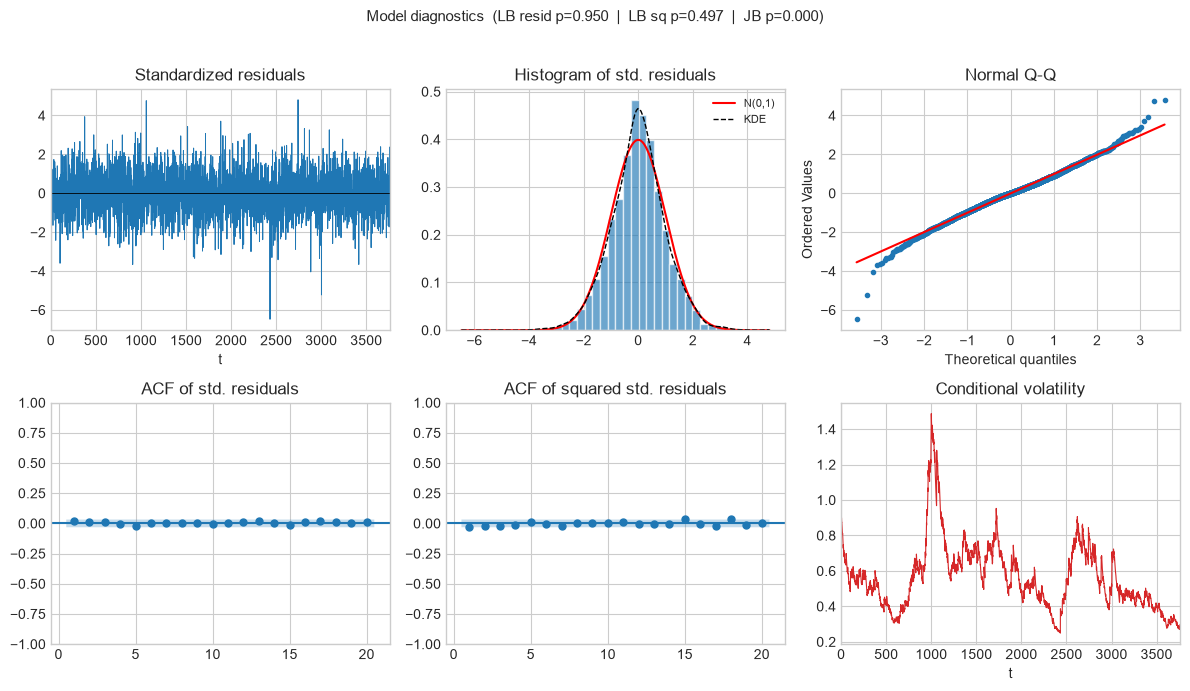

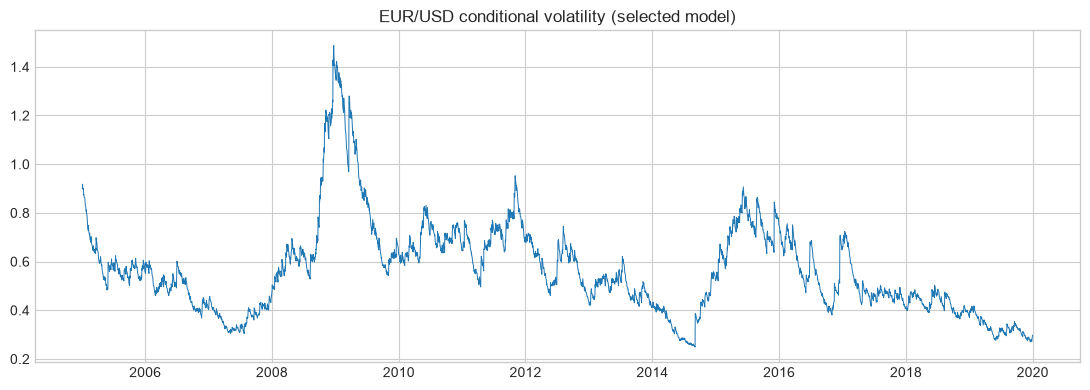

In [12]:
res = best
print("Using select_order best:", table.attrs.get("best"), "BIC=%.2f" % res.bic)
fig = res.plot_diagnostics()
plt.show()
vol = pd.Series(
    np.asarray(res.conditional_volatility, float),
    index=y.index[-len(np.asarray(res.conditional_volatility)):],
)
fig, ax = plt.subplots()
ax.plot(vol, lw=0.7)
ax.set_title("EUR/USD conditional volatility (selected model)")
fig.tight_layout()
plt.show()

## 8. Takeaways

1. FX daily returns: **GARCH (and tails / leverage) first**; mean ARMA is optional and often harmful.
2. Always inspect ARMA(1,1) for **cancellation** (AR ≈ −MA).
3. **`select_order`** makes that conclusion mechanical: same burn-in, BIC ranking across mean × vol × dist.
4. makystats power is also knowing **when to stop** — not only fitting richer models.

Source: FRED `DEXUSEU`.
